# <center> ISEL - PIV </center>
## <center>Semestre 2024/25 </center>
###  <center> 1º Trabalho Laboratorial </center>
###  <center> Contagem e Classificação de Peças de Lego Retangulares</center>

Trabalho realizado por:
* João Ramos, numero <b> 50730 </b>
* Fábio Pestana, numero <b> 50756 </b>

<b> Grupo: 07</b> <br></br>
<b> Turma: 51D </b> <br></br>
<b> Docente: Pedro Mendes Jorge </b>

# Índice
1. [Introdução](#introducao)
2. [Imports](#imports)
3. [Leitura da Imagem](#leitura)
4. [Histograma da Imagem](#histogramas)
5. [Binarização](#binarizacao)
6. [Melhoramento da Imagem](#melhoramento)
7. [Extração de Componentes Conexos](#extracao)
8. [Extração de Propriedades](#propriedades)
    1. [Identificação de contornos retangulares](#contornos)
    2. [Cálculo das dimensões dos objetos retangulares](#calc_dimensoes)
9. [Classificação das Peças de Lego](#classificacao)
10. [Conclusão](#conclusao)

#  Introdução <a name= "introducao"></a>

<div style="text-align: justify">
Este primeiro trabalho laboratorial tem como objetivo desenvolver um algoritmo de visão por computador capaz de contar automaticamente o número de peças retangulares de Lego colocadas sobre uma mesa e classificá-las. O algoritmo foi programado em Python, utilizando a biblioteca OpenCV.

A tarefa central consiste em identificar e classificar peças retangulares de Lego com dimensões específicas ("2x2", "2x4", "2x6" e "2x8") dispostas sobre uma superfície homogénea e clara. A câmara, montada num tripé e ajustada para que o plano do sensor seja paralelo ao plano da mesa, capta imagens que são processadas pelo algoritmo para detetar e classificar automaticamente as peças desejadas.

O algoritmo foi projetado para funcionar mesmo que existam algumas possíveis perturbações no cenário de teste, como a presença de outras peças de Lego no campo de visão, sombras sobre a superfície e eventual contacto entre as peças. Além disso, o desenvolvimento considerou a utilização de um conjunto de imagens de treino para ajustar a lógica de classificação. A avaliação final do algoritmo será efetuada com um conjunto de imagens de teste adquiridas nas mesmas condições das imagens de treino.

Este projeto explora a aplicação de técnicas de visão computacional e processamento de imagem para resolver um problema, proporcionando uma familiarização prática com as funcionalidades da biblioteca OpenCV e os seus recursos para deteção e análise de objetos.
</div>

# Imports <a name= "imports"></a>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

# Leitura da Imagem <a name= "leitura"></a>

<div style="text-align: justify">

Neste bloco de código, realizamos a leitura da imagem original que será usada para a análise e classificação das peças de Lego.  
As variáveis ``fileDir`` e ``fileName`` armazenam, respectivamente, o caminho para o diretório onde as imagens estão localizadas e o nome do arquivo da imagem. Isto facilita a alteração do arquivo que queremos usar sem precisar modificar várias partes do código.  

A função ``cv.imread()`` é utilizada para carregar a imagem especificada. Ela lê a imagem no formato BGR, que é o padrão do OpenCV. Assim criamos uma nova imagem que converte a anterior de BGR para RGB utilizando a função ``cv.cvtColor(img, cv.COLOR_BGR2RGB)``. Isto garante que a imagem seja exibida corretamente no matplotlib, que usa o padrão RGB.  

Por fim decidimos utilizar plots visto que torna a visualização das imagens mais prática.

</div>

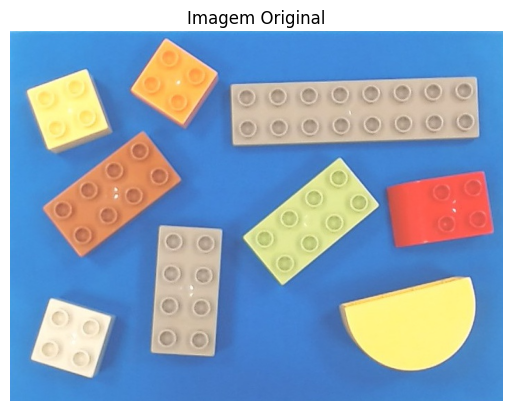

In [11]:
fileDir = 'treino/'
fileName = 'lego01.jpg'

img = (cv.imread(fileDir + fileName))
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis('off')
plt.title('Imagem Original')
plt.show()

# Histograma da Imagem <a name= "histogramas"></a>

<div style="text-align: justify">

Aqui construímos os histogramas de intensidade para cada um dos três canais de cores (azul, verde e vermelho) presentes na imagem original. Isto é importante para entender a distribuição das cores e facilita o processo de binarização, que irá ocorrer posteriormente. Como estamos a lidar com peças de Lego sobre uma mesa azul, o histograma ajudará a identificar e excluir o fundo azul durante a binarização, focando apenas nas peças que queremos classificar.  

Criámos uma função ``Histogram`` que recebe a imagem e o plano de cor (0 para azul, 1 para verde, 2 para vermelho) e retorna um histograma de intensidade para o canal especificado. Utilizamos ``cv.calcHist`` para calcular o histograma. Este conta o número de pixels para cada nível de intensidade (0 a 255) e retorna esses valores como um array. A função é configurada para produzir ``256 bins``, cobrindo todo o intervalo possível de valores de intensidade (0 a 255), que é adequado para imagens de 8 bits. Utilizámos esta função três vezes para calcular os histogramas dos três canais, armazenando os resultados em histBlue, histGreen e histRed.  

Por fim, fizemos plot dos três histogramas.

</div>

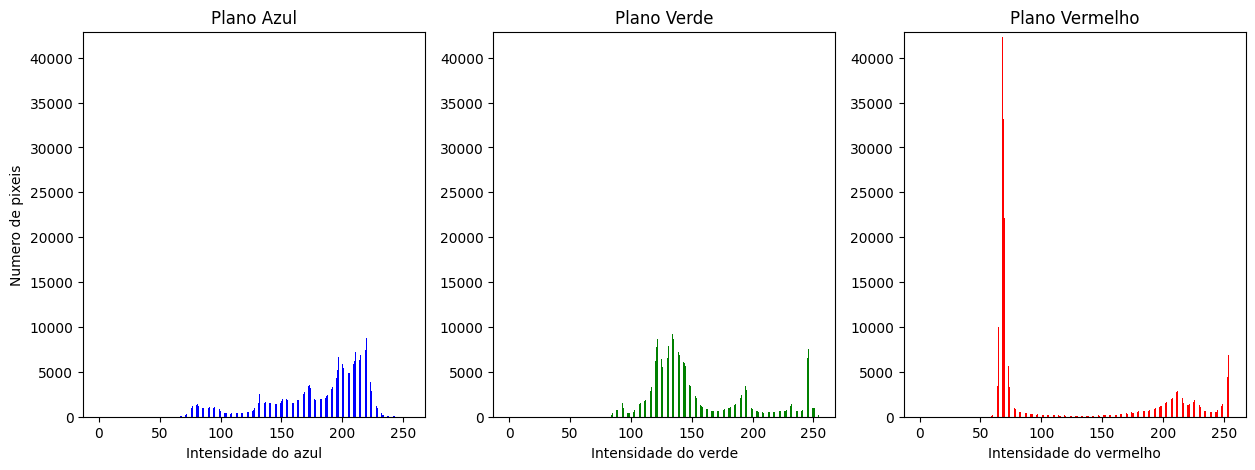

In [12]:
def Histogram(img, colorPlane):
    nbins = 256
    v_range = [0, 255]
    hist = cv.calcHist([img], [colorPlane], None, [nbins], v_range)

    return np.squeeze(hist)

bluePlane = 0
greenPlane = 1
redPlane = 2
width = 0.4
ind = np.arange(256)

histBlue = Histogram(img, bluePlane)
histGreen = Histogram(img, greenPlane)
histRed = Histogram(img, redPlane)

# Garante que todos os gráficos sejam exibidos de maneira uniforme
histMax = max(histGreen.max(), histBlue.max(), histRed.max()) + 500

plt.figure(figsize=(15,5))
plt.subplot(131)
plt.bar(ind, histBlue, width, color='b')
plt.ylim([0, histMax])
plt.xlabel('Intensidade do azul')
plt.ylabel('Numero de pixeis')
plt.title('Plano Azul')

plt.subplot(132)
plt.bar(ind, histGreen, width, color='g')
plt.ylim([0, histMax])
plt.xlabel('Intensidade do verde')
plt.title('Plano Verde')

plt.subplot(133)
plt.bar(ind, histRed, width, color='r')
plt.ylim([0, histMax])
plt.xlabel('Intensidade do vermelho')
plt.title('Plano Vermelho')
plt.show()

# Binarização <a name= "binarizacao"></a>

<div style="text-align: justify">

Este bloco de código tem como objetivo realizar a binarização da imagem para facilitar a identificação e análise das peças de Lego, separando-as do fundo azul da mesa. A binarização converte a imagem para um formato binário (preto e branco), assim destacando os objetos de interesse (peças).  

Primeiramente, a linha ``weights = cv.addWeighted(img[:, :, 1], 0.5, img[:, :, 2], 0.5, 0)`` combina os canais de cor verde (índice 1) e vermelho (índice 2) da imagem original. Dado que o fundo é azul, queremos minimizar a sua influência na imagem binarizada, portanto, optamos por excluir o canal azul (índice 0). A junção dos canais é feita de forma equilibrada (0.5 para cada canal), criando assim uma imagem que não inclui o azul do fundo.  

Além disso, para entender melhor a distribuição das intensidades na imagem resultante da junção dos canais verde e vermelho, é gerado um histograma. Este histograma exibe o número de pixels para cada nível de intensidade (0 a 255), permitindo observar como as cores estão distribuídas na imagem. Uma linha vertical vermelha no gráfico indica o valor do ``threshold (thres)`` calculado pelo método de Otsu, destacando o ponto de corte entre o fundo e os objetos de interesse.

Segundamente, aplicamos a binarização com Otsu através da função ``cv.threshold`` que é utilizada para realizar a binarização da imagem. Utilizámos o método de ``Otsu``, que determina automaticamente um valor de limiar ótimo para separar o fundo dos objetos de interesse (peças de lego), assim tornando os objetos brancos(255) e o fundo preto(0). O resultado é armazenado em bw, que representa a imagem binarizada.  

Por fim, fazemos plot da imagem binarizada ao lado da imagem original.

</div>

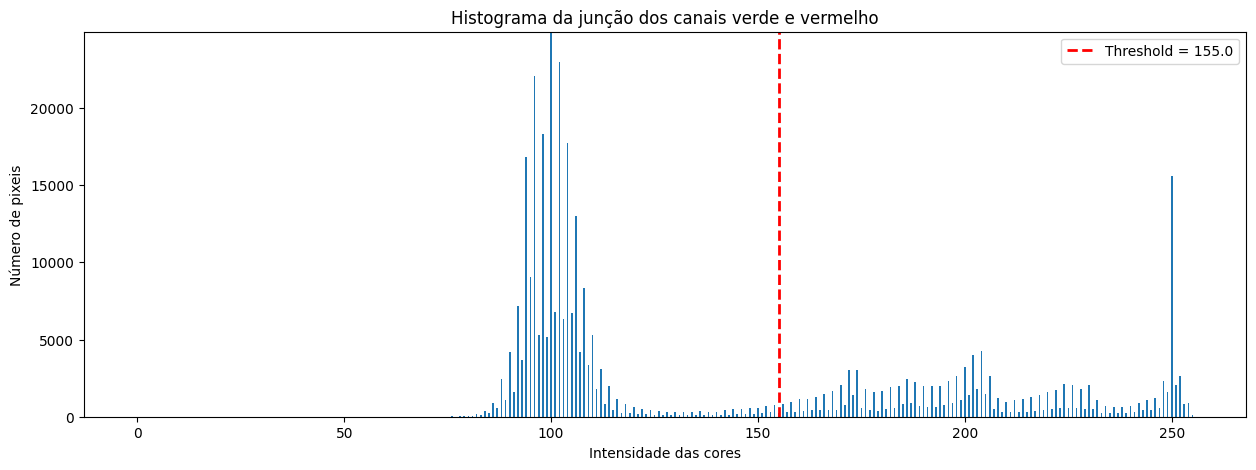

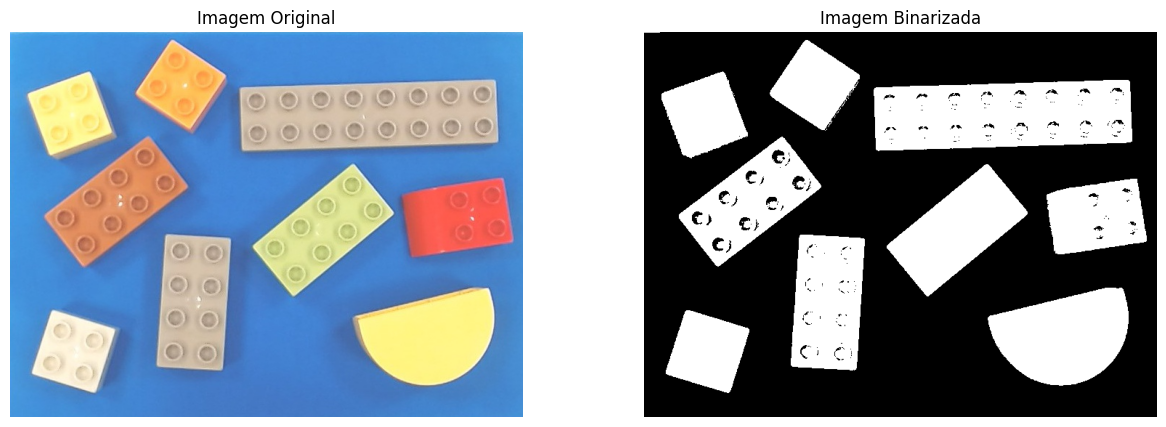

In [13]:
weights = cv.addWeighted(img[:, :, 1], 0.5, img[:, :, 2], 0.5, 0) # excluir o backgorund (blue - indice 0)

thres , bw = cv.threshold(weights, 0, 255, cv.THRESH_OTSU)

# Definindo parâmetros do histograma
nbins = 256
v_range = [0, 256]

hist = cv.calcHist([weights], [0], None, [nbins], v_range)
hist = hist.flatten()
width = 0.4
ind = np.arange(nbins)
histMax = hist.max()

plt.figure(figsize=(15, 5))
plt.bar(ind, hist, width)
plt.ylim([0, histMax])
plt.xlabel('Intensidade das cores')
plt.ylabel('Número de pixeis')
plt.title("Histograma da junção dos canais verde e vermelho")
plt.axvline(x=thres, color='r', linestyle='--', linewidth=2, 
            label=f'Threshold = {thres}')
plt.legend()
plt.show()

plt.figure(figsize=(15, 5))

plt.subplot(121)
plt.imshow(img_rgb)
plt.axis('off')
plt.title('Imagem Original')

plt.subplot(122)
plt.imshow(bw, cmap='gray')
plt.axis('off')
plt.title('Imagem Binarizada')

plt.show()

# Melhoramento da Imagem <a name= "melhoramento"></a>

<div style="text-align: justify">

Neste bloco de código o objetivo é melhorar a imagem binarizada para garantir uma separação mais clara e precisa entre as peças de Lego e o fundo. Para isso, utilizamos operadores morfológicos que ajudam a definir melhor os contornos das peças e removem ruídos indesejados que possam aparecer durante a binarização.

Primeiramente, criamos uma cópia da imagem binarizada (bw) para servir como uma máscara que será manipulada. Usamos a função ``cv.findContours`` para detetar todos os contornos presentes na máscara. Para garantir que todas as peças de Lego sejam preenchidas completamente (e quaisquer buracos internos sejam removidos), aplicámos a função ``cv.drawContours`` com o parâmetro ``-1``, que preenche os contornos detectados com a cor branca (valor 255).

Em seguida, utilizamos o operador morfológico de erosão para melhorar ainda mais a máscara. A função ``cv.erode`` é aplicada usando um elemento estruturante retangular ``(cv.MORPH_RECT)`` de tamanho 8x8 (utilizou-se este valor, pois após vários testes este deu o melhor resultado). A erosão ajuda a eliminar pequenas irregularidades e conexões finas indesejadas entre objetos, tornando as peças mais uniformes e separadas, o que irá ajudar posteriormente a identificar o número de peças na imagem. O resultado dessa operação é armazenado na variável ``img_erode``.

Após a erosão, convertemos img_erode para uma imagem em formato BGR ``(img_erode_bgr)`` para que possamos aplicá-la como uma máscara à imagem original. A máscara processada é então combinada com a imagem original utilizando a função ``cv.bitwise_and``. Isto resulta em uma nova imagem (img_bin) onde apenas as áreas correspondentes às peças de Lego estão visíveis, enquanto o fundo é removido.

Por fim, utilizamos o plt.subplot para exibir uma comparação visual dos diferentes estágios do processo:
* Imagem Binarizada: mostra o resultado da binarização inicial.
* Imagem com Erosão: destaca como o operador morfológico ajudou a remover ruídos e refinar as peças.
* Imagem com Máscara Aplicada: exibe o resultado final, onde apenas as peças de Lego são visíveis, com o fundo removido.

</div>

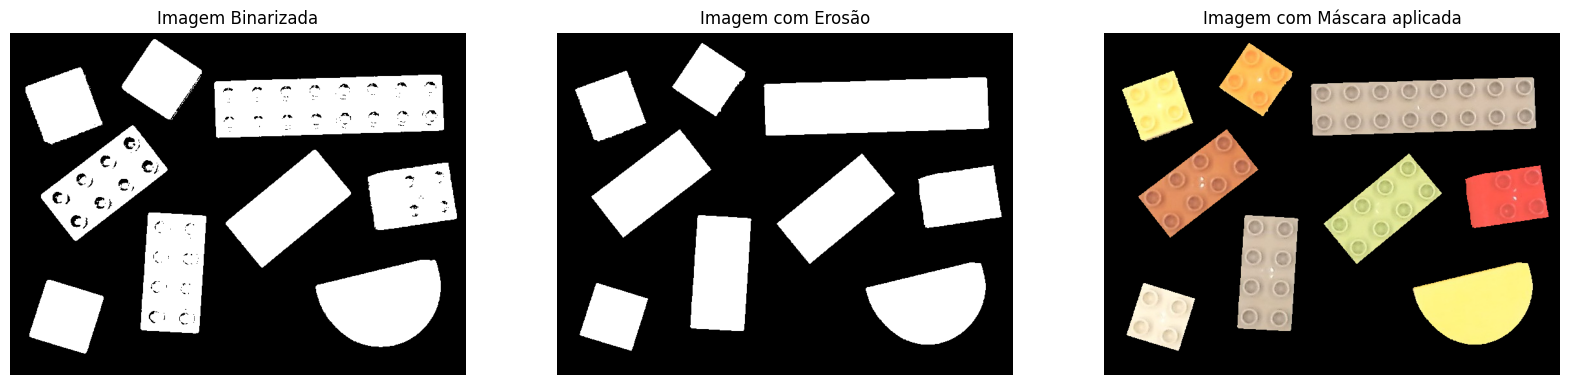

In [14]:
mask = bw.copy()

contours, h = cv.findContours(mask, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)

for c in contours:
    cv.drawContours(mask, [c], 0, 255, -1) 

elements = cv.getStructuringElement(cv.MORPH_RECT, (8, 8))

img_erode = cv.erode(mask, elements)

img_erode_bgr = cv.cvtColor(img_erode, cv.COLOR_GRAY2BGR)

img_bin = cv.bitwise_and(img, img_erode_bgr)

img_bin_rgb = cv.cvtColor(img_bin, cv.COLOR_BGR2RGB)

plt.figure(figsize=(20, 10))

plt.subplot(131)
plt.imshow(bw, cmap='gray')
plt.axis('off')
plt.title('Imagem Binarizada')

plt.subplot(132)
plt.imshow(img_erode, cmap='gray')
plt.axis('off')
plt.title('Imagem com Erosão')

plt.subplot(133)
plt.imshow(img_bin_rgb)
plt.axis('off')
plt.title('Imagem com Máscara aplicada')

plt.show()

# Extração de Componentes Conexos <a name= "extracao"></a>

<div style="text-align: justify">

Neste bloco de código, o objetivo é detectar e destacar os diferentes objetos presentes na imagem processada, identificando cada um deles como um objeto. Isto é fundamental para a análise posterior, onde queremos classificar e distinguir as peças de Lego.

Primeiramente, utilizamos a função ``cv.findContours`` para encontrar os contornos externos dos objetos na imagem erodida (img_erode). Optamos por ``cv.RETR_EXTERNAL`` para garantir que apenas os contornos externos sejam detectados, ignorando quaisquer contornos internos que poderiam gerar falsos positivos (por exemplo, pequenos buracos dentro das peças que possam ter escapado às ações anteriores). O parâmetro ``cv.CHAIN_APPROX_SIMPLE`` ajuda a simplificar a representação dos contornos, reduzindo a quantidade de pontos a serem processados.

Após a detecção, os contornos são desenhados em uma nova imagem (image_with_contours) usando a função ``cv.drawContours``. Os contornos são traçados em vermelho para facilitar a visualização dos objetos identificados.

Em seguida, aplicamos a função ``cv.connectedComponents``, que analisa a imagem processada (img_erode) e atribui uma etiqueta única a cada conjunto de pixels conectados, ou seja, cada peça de Lego detectada. O número total de componentes conexos encontrados é armazenado em ``num_labels``, e a imagem resultante com as etiquetas (labels_im) permite visualizar a distinção entre os diferentes objetos.

Finalmente, utilizamos o plt.subplot para criar uma comparação visual dos diferentes estágios:
* Contornos Detectados: mostra a imagem com os contornos desenhados, permitindo uma visualização clara dos objetos que foram identificados.
* Imagem com Erosão: demonstra o resultado da etapa de erosão, que é a base para a detecção dos componentes.
* Imagem Etiquetada: destaca os objetos na imagem, onde cada componente conexo recebe uma cor diferente, facilitando a distinção das peças de Lego a partir das etiquetas.

No final, fazemos um print do número de objetos detectados (num_labels - 1). Subtraímos 1 porque a contagem de ``cv.connectedComponents`` inclui o fundo da imagem como uma etiqueta (etiqueta 0), que não é considerada um objeto.

</div>

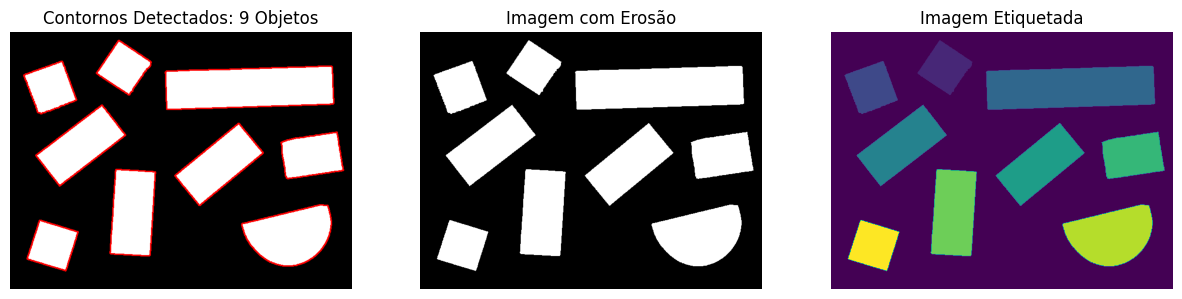

Número de objetos detectados: 9


In [15]:
# Encontra os contornos dos objetos na imagem
contours, hierarchy = cv.findContours(img_erode, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# Desenha os contornos em uma nova imagem
image_with_contours = cv.cvtColor(img_erode, cv.COLOR_GRAY2BGR)
cv.drawContours(image_with_contours, contours, -1, (255, 0, 0), 2)

# Atribui etiquetas aos pixeis da imagem
num_labels, labels_im = cv.connectedComponents(img_erode)

plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(image_with_contours)
plt.axis('off')
plt.title(f'Contornos Detectados: {num_labels -1} Objetos')

plt.subplot(132)
plt.imshow(img_erode, cmap='gray')
plt.axis('off')
plt.title('Imagem com Erosão')

plt.subplot(133)
plt.imshow(labels_im)
plt.axis('off')
plt.title('Imagem Etiquetada')

plt.show()

print(f'Número de objetos detectados: {num_labels -1}')

# Extração de Propriedades <a name= "propriedades"></a>

### Identificação de contornos retangulares <a name= "contornos"></a>

<div style="text-align: justify">

Neste bloco de código, buscámos identificar e distinguir os contornos retangulares dos não retangulares na imagem. Isto é essencial para separar as peças de Lego em categorias que podem ser analisadas de maneira mais específica posteriormente e ajuda a filtrar objetos que não correspondem às formas desejadas.

Primeiramente, criámos uma cópia da imagem erodida (img_erode) e convertemo-la para uma imagem colorida ``(image_ret_or_indef)``. Esta cópia será usada para desenhar contornos de cores diferentes para visualizar facilmente quais objetos são retangulares (desenhados em azul) e quais não o são (desenhados em vermelho).

A seguir, inicializámos duas listas:
* ``rectangular_contours``: para armazenar contornos que se assemelham a retângulos.
* ``non_rectangular_contours``: para armazenar contornos que não são retangulares.

O próximo passo é percorrer cada contorno identificado anteriormente e determinar a sua forma. Para isso, usamos a função ``cv.approxPolyDP``, que aproxima o contorno para um polígono de menos lados, com base em um fator de precisão (epsilon). O valor de epsilon é calculado como 2% do comprimento do arco do contorno, permitindo simplificar os contornos e facilitar a classificação das formas.

Para definir se um contorno é retangular, verificámos se o polígono aproximado resultante possui 4 vértices. Se tiver, o contorno é considerado retangular e adicionado à lista ``rectangular_contours``.Também usamos a função ``cv.minAreaRect`` para calcular o menor retângulo que pode envolver o contorno. A função ``cv.boxPoints`` extrai as coordenadas do retângulo, e os pontos são convertidos a inteiros para desenhá-los na imagem (image_ret_or_indef) em azul.

A razão pela qual usamos ``boxPoints`` para os retângulos é que esta abordagem permite-nos desenhar um contorno que representa a melhor aproximação retangular do objeto. Isto é útil porque, mesmo que o contorno não seja perfeitamente retangular, o retângulo mínimo envolvente fornece uma representação clara da forma do objeto e permite uma melhor visualização das dimensões.

Se o contorno não tiver 4 vértices, ele é classificado como não retangular e adicionado à lista ``non_rectangular_contours``. Nesses casos, o contorno é desenhado diretamente na imagem com a cor vermelha. A razão para desenhar contornos não retangulares diretamente é que eles podem ter formas irregulares e não podem ser simplificados em um retângulo, então o uso do contorno original garante que a forma real do objeto seja representada na imagem.

Ao final do processo, mostramos a imagem resultante usando plt.imshow, onde podemos facilmente distinguir os objetos classificados como retangulares (em azul) dos que não são (em vermelho). Também exibimos na consola a contagem de cada tipo de contorno encontrado.

</div>

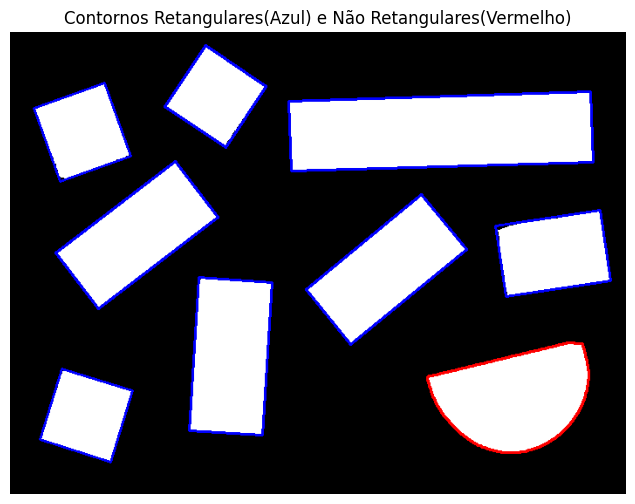

Número de contornos retangulares: 8
Número de contornos não retangulares: 1


In [16]:
# Criar uma copia da imagem com contornos para desta vez diferenciar o que é retangular e o que não o é
image_ret_or_indef = cv.cvtColor(img_erode, cv.COLOR_GRAY2BGR)

# Listas para armazenar os contornos retangulares e não retangulares
rectangular_contours = []
non_rectangular_contours = []

# Loop através dos contornos
for contour in contours:
    # Ajustar o contorno para um polígono aproximado
    epsilon = 0.02 * cv.arcLength(contour, True)
    approx = cv.approxPolyDP(contour, epsilon, True)

    # Verificar se o polígono aproximado tem 4 vértices
    if len(approx) == 4:
        # Adicionar à lista de contornos retangulares
        rectangular_contours.append(contour)
        # Desenhar o retângulo mínimo em azul
        box = cv.minAreaRect(contour)
        box_points = cv.boxPoints(box)
        box_points = np.intp(box_points)
        cv.drawContours(image_ret_or_indef, [box_points], 0, (255, 0, 0), 2)
    else:
        # Adicionar à lista de contornos não retangulares
        non_rectangular_contours.append(contour)
        # Desenhar o contorno não retangular em vermelho
        cv.drawContours(image_ret_or_indef, [contour], -1, (0, 0, 255), 2)


plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(image_ret_or_indef, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Contornos Retangulares(Azul) e Não Retangulares(Vermelho)')
plt.show()

print(f'Número de contornos retangulares: {len(rectangular_contours)}')
print(f'Número de contornos não retangulares: {len(non_rectangular_contours)}')

### Cálculo das dimensões dos objetos retangulares <a name= "calc_dimensoes"></a>

<div style="text-align: justify">

Visto que existe a possibilidade de um dos objetos ser retangular mas não fazer parte das peças que queremos classificar, iremos também calcular as dimensões dos objetos para assim podermos verificar os intervalos das dimensões das peças que queremos classificar.

Primeiramente, fazemos uma cópia da imagem que já possui os contornos desenhados (image_ret_or_indef) para que possamos adicionar números sobre cada objeto retangular. Isto permitirá identificar a qual retângulo as dimensões pertencem.

Em seguida, inicializamos uma lista chamada ``rect_dimensions``, que será usada para armazenar as dimensões (largura e altura) de cada objeto retangular. Essa informação será útil para a análise posterior, onde verificaremos se as dimensões dos objetos enquadram-se nos intervalos definidos para as peças de Lego que estamos a classificar.

Para calcular as dimensões, percorremos cada contorno retangular armazenado na lista ``rectangular_contours`` ao usar a função ``enumerate``, que também nos fornece um índice (idx) que começa em 1.  
Para cada contorno utilizámos ``cv.minAreaRect(contour)`` para obter o retângulo mínimo que envolve o contorno. Extraímos a largura e a altura do retângulo e armazenamos esses valores na lista ``rect_dimensions``. Calculámos também o centro do retângulo, que será utilizado para posicionar o número sobre o objeto na imagem.

A função ``cv.putText`` é então usada para desenhar o número correspondente ao objeto no centro do retângulo.
Após iterar por todos os contornos retangulares, exibimos a imagem resultante, que agora contém os números sobre os objetos retangulares, permitindo que indentifiquemos a qual retângulo as dimensões pertencem.

Finalmente, imprimimos as dimensões dos objetos retangulares na consola. Assim, podemos avaliar as dimensões dos objetos encontrados, que serão utilizadas na próxima etapa para determinar se esses objetos se encaixam nos critérios de classificação das peças de Lego (como 2x2, 2x4, 2x6 ou 2x8).

</div>

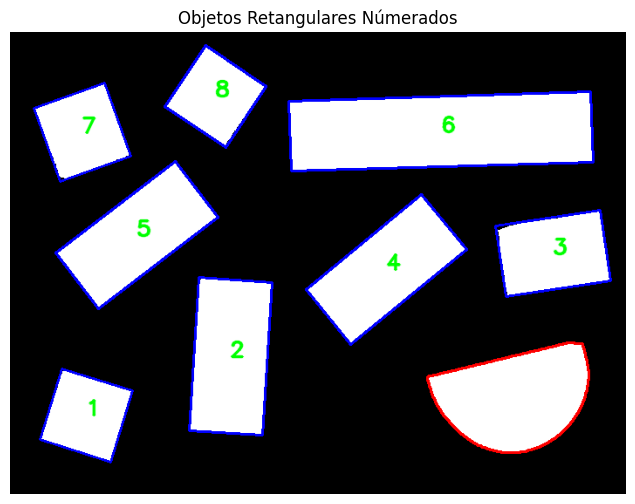

Dimensões dos objetos retangulares (Largura x Altura):
Objeto 1: 85.18 x 85.41 pixels
Objeto 2: 83.98 x 175.72 pixels
Objeto 3: 81.55 x 120.68 pixels
Objeto 4: 80.79 x 171.80 pixels
Objeto 5: 80.60 x 172.91 pixels
Objeto 6: 80.43 x 346.17 pixels
Objeto 7: 89.11 x 86.42 pixels
Objeto 8: 84.30 x 83.76 pixels


In [17]:
# Cópia da imagem para exibir os números sobre cada objeto retangular
image_ret_or_indef_numbered = image_ret_or_indef.copy()

# Lista para armazenar as dimensões dos objetos retangulares
rect_dimensions = []

# Calcular as dimensões dos contornos retangulares e adicionar números à imagem
for idx, contour in enumerate(rectangular_contours, start=1):
    # Obter o retângulo mínimo que envolve o contorno
    box = cv.minAreaRect(contour)
    width, height = box[1]
    rect_dimensions.append((width, height))
    
    # Calcular o centro do retângulo para posicionar o número
    center = np.intp(box[0])
    
    # Escrever o número do objeto na imagem
    cv.putText(image_ret_or_indef_numbered, str(idx), 
               (center[0], center[1]), cv.FONT_HERSHEY_SIMPLEX,
                 0.8, (0, 255, 0), 2, cv.LINE_AA)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(image_ret_or_indef_numbered, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Objetos Retangulares Númerados')
plt.show()

print("Dimensões dos objetos retangulares (Largura x Altura):")
for i, (w, h) in enumerate(rect_dimensions, start=1):
    print(f"Objeto {i}: {w:.2f} x {h:.2f} pixels")

# Classificação das Peças de Lego <a name= "classificacao"></a>

<div style="text-align: justify">

Ao usar este processo para as diversas imagens de treino podemos tirar os seguintes intervalos para as peças 2x2, 2x4, 2x6, 2x8.
* 2x2 = w[78 - 91] h[78 - 91]
* 2x4 = w[78 - 91] h[168 - 180]
* 2x6 = w[78 - 91] h[258 - 270]
* 2x8 = w[78 - 91] h[345 - 355]

</div>

<div style="text-align: justify">

Agora com os intervalos das dimensões das peças podemos passar à classificação.

Para iniciar, fazemos uma cópia da imagem binarizada ``img_classified_bin`` e outra da imagem original ``img_classified``. Estas cópias serão utilizadas para exibir as classificações em dois formatos diferentes, uma em uma imagem binarizada e a outra na imagem original.

Definimos um dicionário chamado ``ranges``, que contém os limites de dimensões para cada tipo de peça que desejamos classificar, como 2x2, 2x4, 2x6 e 2x8. Os valores especificados representam a largura e a altura mínima e máxima para cada tipo de peça, isto ajuda a determinar se uma peça se encaixa nas categorias desejadas. Também criámos um dicionário de contagem para guardar o número de cada tipo de peça.

A seguir, implementámos a função ``is_within_range``, que verifica se as dimensões de um objeto (largura e altura) estão dentro dos limites especificados para cada tipo de peça. Esta função garante que o maior valor seja considerado a altura, tornando a verificação mais flexível, independentemente da orientação da peça.

O primeiro loop percorre os contornos não retangulares. Para cada contorno não retangular:
* Desenhámos um contorno vermelho na imagem binarizada para indicar que não é um objeto retangular.
* Calculamos o centro do contorno utilizando a função ``cv.moments``. Se o momento não for zero, obtemos as coordenadas do centro e utilizamos ``cv.putText`` para escrever "Indef." na imagem, tanto na versão colorida quanto na binarizada.

Em seguida, o segundo loop percorre apenas os contornos retangulares, onde utilizamos ``cv.minAreaRect`` para obter o retângulo mínimo que envolve cada contorno. Extraímos a largura e a altura do retângulo e chamamos a função ``is_within_range`` para verificar se as dimensões correspondem a uma das peças especificadas.

* Se as dimensões correspondem a uma peça, desenhamos um contorno azul na imagem binarizada e escrevemos o tipo da peça no centro do retângulo, usando a mesma abordagem para obter as coordenadas do centro.
* Se as dimensões não corresponderem a nenhuma das peças especificadas, desenhamos um contorno vermelho e anotamos "Indef." no centro do objeto, indicando que não se trata de uma peça classificada.

Por fim, exibimos as duas imagens: a versão binarizada com os contornos e classificações, e a imagem original com as mesmas informações (adicionou-se no canto superior esquerdo desta a quantidade de cada tipo de peça). 
Antes dos plots encontra-se a quantidade de cada tipo de peça.

</div>

Pecas 2x2: 3
Pecas 2x4: 3
Pecas 2x6: 0
Pecas 2x8: 1
Total de peças indefinidas: 2


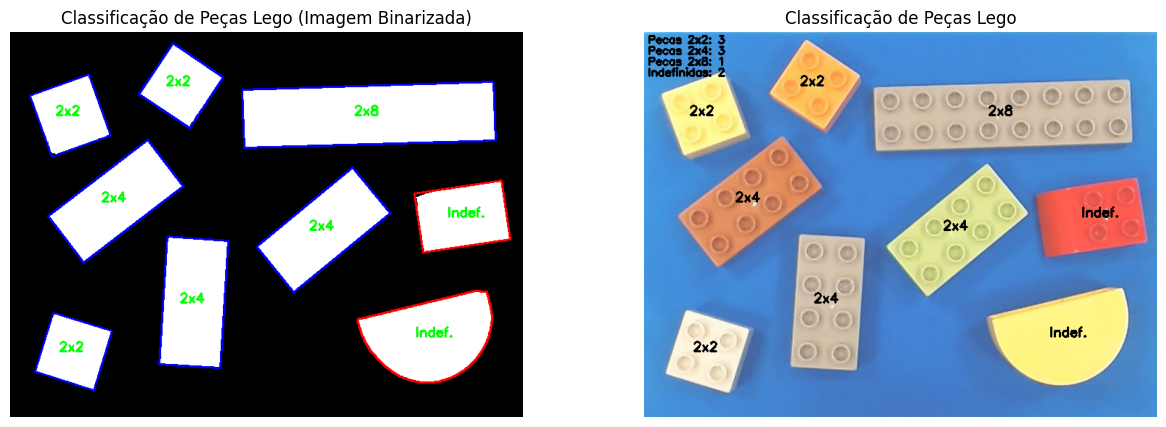

In [18]:
# Imagem para classificação
img_classified_bin = cv.cvtColor(img_erode, cv.COLOR_GRAY2BGR)
img_classified = img_rgb.copy()

# Definir os ranges de dimensões para cada tipo de peça
ranges = {
    "2x2": (78, 91, 78, 91),
    "2x4": (78, 91, 168, 180),
    "2x6": (78, 91, 258, 270),
    "2x8": (78, 91, 345, 355)
}

# Variáveis para contar cada tipo de peça
count_indef = 0
contador_pecas = {key: 0 for key in ranges.keys()}

# Função para verificar se as dimensões estão dentro dos ranges permitidos
def is_within_range(width, height, ranges):
    # Certificar que o maior valor seja considerado a altura
    w, h = min(width, height), max(width, height)
    
    for key, (w_min, w_max, h_min, h_max) in ranges.items():
        if w_min <= w <= w_max and h_min <= h <= h_max:
            return key  # Retorna o tipo da peça correspondente
    return None

# Loop para percorrer os contornos não retangulares
for contour in non_rectangular_contours:
    # Desenhar contorno vermelho para peças não retangulares
    cv.drawContours(img_classified_bin, [contour], -1, (0, 0, 255), 2)
    # Obter o centro do contorno para escrever a classificação
    M = cv.moments(contour)
    if M["m00"] != 0:  # Evitar divisão por zero
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])
        cv.putText(img_classified, 'Indef.', (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
        cv.putText(img_classified_bin, 'Indef.', (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        count_indef += 1  # Aumenta o contador de peças indefinidas

# Loop para percorrer apenas os contornos retangulares e classificar os objetos com base nas dimensões
for contour in rectangular_contours:
    # Obter o retângulo mínimo que envolve o contorno
    box = cv.minAreaRect(contour)
    width, height = box[1]
    
    # Verificar se as dimensões correspondem a qualquer uma das peças especificadas
    piece_type = is_within_range(width, height, ranges)
    box_points = cv.boxPoints(box)
    box_points = np.intp(box_points)

    # Desenhar contorno e adicionar texto
    if piece_type is not None:
        # Desenhar contorno azul para peças com dimensões correspondentes
        cv.drawContours(img_classified_bin, [box_points], 0, (255, 0, 0), 2)
        # Obter o centro do retângulo para escrever a classificação
        M = cv.moments(contour)
        if M["m00"] != 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            cv.putText(img_classified, piece_type, (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
            cv.putText(img_classified_bin, piece_type, (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        
        # Atualizar o contador correspondente
        contador_pecas[piece_type] +=1
        
    else:
        # Desenhar contorno vermelho para peças não correspondentes
        cv.drawContours(img_classified_bin, [box_points], 0, (0, 0, 255), 2)
        # Obter o centro do retângulo para escrever a classificação
        M = cv.moments(contour)
        if M["m00"] != 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            cv.putText(img_classified, 'Indef.', (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
            cv.putText(img_classified_bin, 'Indef.', (cX - 20, cY), cv.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        count_indef += 1  # Aumenta o contador de peças indefinidas


text_y = 15
for key, contador in contador_pecas.items():
    str_peca_contador = f"Pecas {key}: {contador}"
    if contador != 0:
        cv.putText(img_classified, str_peca_contador, (5, text_y), cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 2)
        text_y +=15
    print(str_peca_contador)

if count_indef != 0:
    texto_indf =  f"Indefinidas: {count_indef}"
    cv.putText(img_classified, texto_indf, (5, text_y), cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 2)
print(f"Total de peças indefinidas: {count_indef}")

plt.figure(figsize=(15, 5))

plt.subplot(121)
plt.imshow(cv.cvtColor(img_classified_bin, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Classificação de Peças Lego (Imagem Binarizada)')

plt.subplot(122)
plt.imshow(img_classified)
plt.axis('off')
plt.title('Classificação de Peças Lego')

plt.show()

# Conclusão <a name= "conclusao"></a>

<div style="text-align: justify">

O desenvolvimento deste trabalho possibilitou a criação de um algoritmo para a identificação e contagem de peças de Lego retangulares sobre uma superfície homogénea e clara. Utilizando técnicas de visão por computador com a biblioteca OpenCV, conseguimos alcançar os objetivos propostos, destacando os seguintes pontos principais:
* Eficiência na Separação do Fundo e Objeto de Interesse: A utilização de técnicas de combinação de canais e binarização automática pelo método de Otsu permitiu uma segmentação precisa das peças de Lego, eliminando a influência do fundo azul e destacando os objetos de interesse.

* Análise Estrutural dos Objetos: A extração de contornos e a classificação baseada nas características geométricas (formas retangulares) possibilitou identificar e separar peças retangulares de outros objetos. O uso de retângulos mínimos garantiu que as dimensões dos objetos fossem corretamente avaliadas, mesmo quando as peças estavam em contacto.

* Classificação Precisa: Com base nas dimensões estabelecidas, o algoritmo conseguiu classificar corretamente as peças de Lego em categorias predefinidas (2x2, 2x4, 2x6 e 2x8). As peças que não se encaixavam em nenhuma dessas dimensões foram classificadas como indefinidas.

Ao longo do desenvolvimento, foram corrigidos problemas como a presença de sombras, contactos entre peças e a presença de outros objetos fora da lista dos que queremos classificar. A robustez e precisão do algoritmo foram validadas através da análise do conjunto de imagens de treino. O grupo encontrou-se num problema na imagem de treino número 10, em que, pelo facto do cabelo do boneco de lego ser preto, ele também é considerado como fundo após a imagem ser binarizada. Isto acaba por fazer com que o programa ache que os braços do boneco são 2 objetos distintos e acaba por informar um número errado de peças presentes na imagem.

Em resumo, o projeto foi bem-sucedido em cumprir os objetivos propostos, e proporcionou um aprofundamento significativo nas técnicas de visão por computador com ajuda da biblioteca OpenCV.
</div>